# Notebook 02 · Pipeline, trois modèles, Optuna et journal des essais

On entraîne deux classifications binaires sur l'entraînement 2010-2021 (143 mois) :
- **Nikkei** : *y* = 1 si le Nikkei **baisse** le mois suivant (classe positive = l'événement rare et coûteux, S7). Le modèle donne P(baisse) ; la probabilité de hausse du manuel est p<sub>t</sub> = 1 − P(baisse).
- **Couverture** : *y* = 1 si **ne pas couvrir** le yen était mieux le mois suivant.

| Exigence de l'énoncé | Où |
|---|---|
| 3. Déséquilibre | `class_weight` testé par Optuna (section 4) ; le seuil de décision suit au notebook 03 |
| 4. Trois modèles, mêmes métriques | régression logistique, Random Forest, LightGBM (sections 5 et 6) |
| 5. Une seule `Pipeline` | section 2 |
| 6. Optuna avec une validation croisée honnête | `TimeSeriesSplit`, sections 3 et 4 |
| 7. Journal des essais | `runs/trials_log.csv`, section 4 |

Le test (2024-2026) n'est pas touché ici. La validation (2022-2023) sert seulement à comparer les modèles déjà réglés.

In [1]:
from pathlib import Path
import json
import subprocess
import time
import warnings
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import yaml
from lightgbm import LGBMClassifier
from optuna.samplers import TPESampler
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message=".*feature names.*")
optuna.logging.set_verbosity(optuna.logging.WARNING)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CFG = yaml.safe_load(open(ROOT / "config.yaml"))
SEED = CFG["seed"]
FIG = ROOT / "figures"
RUNS = ROOT / "runs"
(RUNS / "models").mkdir(parents=True, exist_ok=True)
COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
DATE = datetime.now().strftime("%Y-%m-%d %H:%M")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

table = pd.read_csv(ROOT / CFG["data"]["model_table"], parse_dates=["date"]).set_index("date")
FEATURES = [c for groupe in ["news", "price", "macro", "fx"] for c in CFG["features"][groupe]]
REGIME = CFG["features"]["regime"]
COLONNES = FEATURES + [c for c in REGIME if c not in FEATURES]
CIBLES = {"nikkei": "y_baisse", "couverture": "y_non_couvert"}

train = table[table["bloc"] == "entraînement"]
valid = table[table["bloc"] == "validation"]
X_tr, X_va = train[COLONNES], valid[COLONNES]
print(f"entraînement : {len(train)} mois ({train.index[0]:%Y-%m} → {train.index[-1]:%Y-%m}) | "
      f"validation : {len(valid)} mois | commit {COMMIT}")

entraînement : 143 mois (2010-02 → 2021-12) | validation : 24 mois | commit 2cbac44


## 1. Combien de régimes de marché ? Le coude du k-means (L3B)

Le k-means regroupe les mois selon trois variables de risque standardisées : volatilité EWMA du Nikkei, rendement du mois, VIX. On le calcule sur l'**entraînement seulement**. L'inertie (WCSS, la somme des distances au carré au centre de son groupe) baisse toujours quand on ajoute des groupes : on cherche le coude, là où ajouter un groupe n'apporte plus grand-chose.

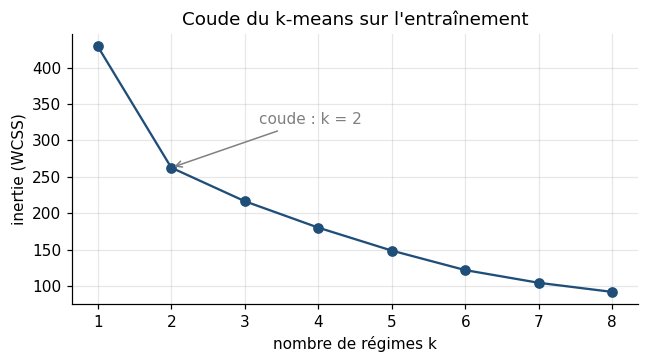

baisse de l'inertie en ajoutant un groupe (%) : [38.8, 17.5, 16.8, 17.5, 18.0, 14.3, 12.0]


In [2]:
scaler_regime = StandardScaler().fit(train[REGIME])
Z = scaler_regime.transform(train[REGIME])
ks = range(1, 9)
wcss = [KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z).inertia_ for k in ks]

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(list(ks), wcss, marker="o", color="#1f4e79")
ax.annotate("coude : k = 2", xy=(2, wcss[1]), xytext=(3.2, wcss[1] + 60),
            arrowprops=dict(arrowstyle="->", color="grey"), color="grey")
ax.set_xlabel("nombre de régimes k")
ax.set_ylabel("inertie (WCSS)")
ax.set_title("Coude du k-means sur l'entraînement")
fig.tight_layout()
fig.savefig(FIG / "02_coude_kmeans.png")
plt.show()

baisse = [100 * (a - b) / a for a, b in zip(wcss, wcss[1:])]
print("baisse de l'inertie en ajoutant un groupe (%) :", [round(x, 1) for x in baisse])

In [3]:
K_REGIMES = 2
km = KMeans(n_clusters=K_REGIMES, n_init=10, random_state=SEED).fit(Z)
centres = pd.DataFrame(scaler_regime.inverse_transform(km.cluster_centers_), columns=REGIME)
centres["mois"] = np.bincount(km.labels_)
centres.index = [f"régime {i}" for i in range(K_REGIMES)]
centres.round(3)

,n225_vol_ewma,n225_ret_1m,vix,mois
régime 0,0.283,-0.045,27.300,31
régime 1,0.171,0.024,15.635,112


Passer de 1 à 2 régimes fait baisser l'inertie de près de 40 %. Ensuite, chaque groupe de plus ne la baisse que de 12 à 19 % : le coude est à **k = 2**. On obtient un régime calme, la grande majorité des mois, et un régime agité : volatilité forte, rendement du mois négatif, VIX élevé. Dans la pipeline, le k-means est réajusté dans chaque fold, et le modèle reçoit la distance du mois à chacun des deux centres.

## 2. Une seule pipeline (exigence 5)

Tout ce qui apprend un paramètre sur les données est dans la pipeline, donc réajusté sur le fold d'entraînement seulement (S1, S3) : la médiane d'imputation, la moyenne et l'écart-type de standardisation, les centres du k-means. Seule la dernière étape change d'un modèle à l'autre.

In [4]:
def construire_pipeline(modele, k=K_REGIMES):
    regime = Pipeline([("impute", SimpleImputer(strategy="median")),
                       ("scale", StandardScaler()),
                       ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=SEED))])
    prep = ColumnTransformer([("vars", SimpleImputer(strategy="median"), FEATURES),
                              ("regime", regime, REGIME)])
    return Pipeline([("prep", prep), ("scale", StandardScaler()), ("model", modele)])

NOMS_SORTIE = FEATURES + [f"distance_regime_{i}" for i in range(K_REGIMES)]
essai = construire_pipeline(LogisticRegression(max_iter=1000)).fit(X_tr, train["y_baisse"])
print(essai)
print(f"\n{len(COLONNES)} colonnes en entrée → {essai[:-1].transform(X_tr.iloc[:2]).shape[1]} colonnes en sortie de la préparation")

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('vars',
                                                  SimpleImputer(strategy='median'),
                                                  ['news_attention_6m',
                                                   'news_sent_w', 'news_dispo',
                                                   'n225_mom_12m',
                                                   'n225_mom_3m',
                                                   'n225_vol_ewma',
                                                   'd_jgb10y_bp',
                                                   'tankan_large_manuf',
                                                   'carry_1m',
                                                   'eurjpy_rvol_1m']),
                                                 ('regime',
                                                  Pipeline(steps=[('impute',
                                                                   Sim

## 3. Validation croisée temporelle (S1)

`TimeSeriesSplit` en 4 folds de 12 mois : chaque fold s'entraîne sur tout le passé et se valide sur l'année qui suit. Jamais de mélange, jamais de futur dans l'entraînement. La référence de chaque fold est le modèle constant, qui annonce la fréquence observée dans son propre entraînement.

In [5]:
tscv = TimeSeriesSplit(n_splits=4, test_size=12)
FOLDS = list(tscv.split(X_tr))
pd.DataFrame([{"fold": i + 1,
               "entraînement": f"{train.index[a[0]]:%Y-%m} → {train.index[a[-1]]:%Y-%m}",
               "mois entraînement": len(a),
               "mois avec news": int(train["news_dispo"].iloc[a].sum()),
               "validation": f"{train.index[b[0]]:%Y-%m} → {train.index[b[-1]]:%Y-%m}",
               "baisses en validation": int(train["y_baisse"].iloc[b].sum()),
               "yen fort en validation": int(train["y_non_couvert"].iloc[b].sum())}
              for i, (a, b) in enumerate(FOLDS)]).set_index("fold")

,entraînement,mois entraînement,mois avec news,validation,baisses en validation,yen fort en validation
fold,,,,,,
1,2010-02 → 2017-12,95,9,2018-01 → 2018-12,5,7
2,2010-02 → 2018-12,107,21,2019-01 → 2019-12,4,6
3,2010-02 → 2019-12,119,33,2020-01 → 2020-12,4,5
4,2010-02 → 2020-12,131,45,2021-01 → 2021-12,6,6


In [6]:
def evaluer_cv(pipe, y):
    # Métriques moyennes sur les 4 folds et prédictions hors fold
    pertes, briers, praucs = [], [], []
    oof = pd.Series(np.nan, index=y.index)
    for a, b in FOLDS:
        modele = clone(pipe).fit(X_tr.iloc[a], y.iloc[a])
        p = modele.predict_proba(X_tr.iloc[b])[:, 1]
        yb = y.iloc[b]
        pertes.append(log_loss(yb, p, labels=[0, 1]))
        briers.append(brier_score_loss(yb, p))
        praucs.append(average_precision_score(yb, p))
        oof.iloc[b] = p
    return {"logloss": float(np.mean(pertes)), "logloss_std": float(np.std(pertes)),
            "brier": float(np.mean(briers)), "pr_auc": float(np.mean(praucs)),
            "logloss_folds": [round(float(x), 4) for x in pertes]}, oof

def reference_constante(y):
    pertes = [log_loss(y.iloc[b], np.full(len(b), y.iloc[a].mean()), labels=[0, 1]) for a, b in FOLDS]
    briers = [brier_score_loss(y.iloc[b], np.full(len(b), y.iloc[a].mean())) for a, b in FOLDS]
    praucs = [y.iloc[b].mean() for a, b in FOLDS]
    return {"logloss": float(np.mean(pertes)), "brier": float(np.mean(briers)), "pr_auc": float(np.mean(praucs))}

REF_CV = {cible: reference_constante(train[col].astype(int)) for cible, col in CIBLES.items()}
pd.DataFrame(REF_CV).T.round(4).rename_axis("modèle constant, moyenne des 4 folds")

,logloss,brier,pr_auc
"modèle constant, moyenne des 4 folds",,,
nikkei,0.6723,0.2396,0.3958
couverture,0.6973,0.2521,0.5000


## 4. Optuna : réglage des trois modèles et journal des essais (exigences 3, 6, 7)

- **Critère** : la log-loss moyenne des 4 folds. Elle juge la qualité des probabilités sans dépendre d'un seuil (S2).
- **50 essais par modèle**, échantillonneur TPE avec une graine fixée : le réglage se refait à l'identique.
- **Déséquilibre (exigence 3, S7)** : `class_weight` fait partie de l'espace de recherche (`None` ou `"balanced"`). `balanced` change la loss et tire les probabilités vers 50 % ; la log-loss le pénalise si cela n'aide pas. L'autre remède du cours, le seuil de décision, est réglé au notebook 03.
- **Score non optimiste (exigence 6)** : la log-loss de validation croisée sert à choisir les réglages. Les modèles retenus sont ensuite jugés sur la validation 2022-2023, qui n'a servi à aucun choix ici.
- **Journal (exigence 7)** : chaque essai est écrit dans `runs/trials_log.csv`, avec ses paramètres, ses métriques, le commit Git, et le modèle sauvegardé quand l'essai est retenu.

| Modèle | Séance | Espace de recherche |
|---|---|---|
| Régression logistique | S2, S3 | C de 0,001 à 10 (log) ; pénalité L1 ou L2 ; `class_weight` |
| Random Forest | S4, S5 | 100 à 500 arbres ; profondeur 2 à 4 ; 5 à 15 mois par feuille ; `max_features` √d ou 0,5 ; `class_weight` |
| LightGBM | S5 | 50 à 300 arbres ; learning rate 0,01 à 0,1 (log) ; 4 à 8 feuilles ; 5 à 15 mois par feuille ; `reg_lambda` 0 à 5 ; `class_weight` |

Le modèle de couverture n'est réglé qu'en régression logistique : sur l'entraînement, aucune variable ne sort du bruit pour cette cible (notebook 01).

**Choix du solveur de la logistique : `saga`, pas `liblinear`.** `liblinear` pénalise aussi l'intercept *b*. Avec une forte régularisation, il ramène alors toutes les probabilités vers 50 % au lieu de la fréquence réelle (environ 39 % de baisses). Une première exécution l'a montré : la logistique annonçait 51 % de baisses en moyenne sur la validation, et le modèle de couverture était devenu un pile ou face à 50 %. `saga` ne pénalise pas *b*, exactement comme la pénalité de l'annexe de Maths : λ‖w‖² ne porte que sur les poids.

In [7]:
def proposer(trial, nom):
    poids = trial.suggest_categorical("class_weight", [None, "balanced"])
    if nom == "logit":
        return LogisticRegression(C=trial.suggest_float("C", 1e-3, 10, log=True),
                                  penalty=trial.suggest_categorical("penalty", ["l1", "l2"]),
                                  solver="saga", class_weight=poids, max_iter=5000)
    if nom == "rf":
        return RandomForestClassifier(n_estimators=trial.suggest_int("n_estimators", 100, 500, step=100),
                                      max_depth=trial.suggest_int("max_depth", 2, 4),
                                      min_samples_leaf=trial.suggest_int("min_samples_leaf", 5, 15),
                                      max_features=trial.suggest_categorical("max_features", ["sqrt", 0.5]),
                                      class_weight=poids, random_state=SEED, n_jobs=-1)
    if nom == "lgbm":
        return LGBMClassifier(n_estimators=trial.suggest_int("n_estimators", 50, 300, step=25),
                              learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
                              num_leaves=trial.suggest_int("num_leaves", 4, 8),
                              min_child_samples=trial.suggest_int("min_child_samples", 5, 15),
                              reg_lambda=trial.suggest_float("reg_lambda", 0.0, 5.0),
                              class_weight=poids, random_state=SEED, n_jobs=1, verbose=-1)
    raise ValueError(nom)

def objectif(cible, nom):
    y = train[CIBLES[cible]].astype(int)
    def f(trial):
        res, _ = evaluer_cv(construire_pipeline(proposer(trial, nom)), y)
        for cle in ["logloss_std", "brier", "pr_auc", "logloss_folds"]:
            trial.set_user_attr(cle, res[cle])
        return res["logloss"]
    return f

N_ESSAIS = 50
PLAN = [("nikkei", "logit"), ("nikkei", "rf"), ("nikkei", "lgbm"), ("couverture", "logit")]
ETUDES = {}
for cible, nom in PLAN:
    debut = time.time()
    etude = optuna.create_study(direction="minimize", sampler=TPESampler(seed=SEED), study_name=f"{cible}_{nom}")
    etude.optimize(objectif(cible, nom), n_trials=N_ESSAIS)
    ETUDES[(cible, nom)] = etude
    print(f"{cible:10s} {nom:5s} : meilleure log-loss CV {etude.best_value:.4f} (essai {etude.best_trial.number}, "
          f"constante {REF_CV[cible]['logloss']:.4f}) en {time.time() - debut:.0f} s")

nikkei     logit : meilleure log-loss CV 0.6473 (essai 43, constante 0.6723) en 5 s
nikkei     rf    : meilleure log-loss CV 0.6288 (essai 21, constante 0.6723) en 38 s
nikkei     lgbm  : meilleure log-loss CV 0.5836 (essai 49, constante 0.6723) en 6 s
couverture logit : meilleure log-loss CV 0.6875 (essai 26, constante 0.6973) en 5 s


In [8]:
lignes = []
for (cible, nom), etude in ETUDES.items():
    for t in etude.trials:
        retenu = t.number == etude.best_trial.number
        lignes.append({"date": DATE, "commit": COMMIT, "cible": cible, "modele": nom, "essai": t.number,
                       "params": json.dumps(t.params), "cv_logloss": round(t.value, 5),
                       "cv_logloss_std": round(t.user_attrs["logloss_std"], 5),
                       "cv_brier": round(t.user_attrs["brier"], 5), "cv_pr_auc": round(t.user_attrs["pr_auc"], 5),
                       "logloss_par_fold": json.dumps(t.user_attrs["logloss_folds"]), "retenu": retenu,
                       "artefact_modele": f"runs/models/{cible}_{nom}.joblib" if retenu else "",
                       "figure": "figures/02_optuna_historique.png"})
JOURNAL = pd.DataFrame(lignes)
JOURNAL.to_csv(RUNS / "trials_log.csv", index=False)
print(f"runs/trials_log.csv : {len(JOURNAL)} essais")
JOURNAL[JOURNAL["retenu"]].drop(columns=["date", "figure"])

runs/trials_log.csv : 200 essais


,commit,cible,modele,essai,params,cv_logloss,cv_logloss_std,cv_brier,cv_pr_auc,logloss_par_fold,retenu,artefact_modele
43,2cbac44,nikkei,logit,43,"{""class_weight"": null, ""C"": 0.0299352548459898...",0.64727,0.04726,0.22782,0.63200,"[0.7105, 0.5783, 0.659, 0.6413]",True,runs/models/nikkei_logit.joblib
71,2cbac44,nikkei,rf,21,"{""class_weight"": null, ""n_estimators"": 100, ""m...",0.62885,0.02960,0.21931,0.59468,"[0.6606, 0.5872, 0.6149, 0.6527]",True,runs/models/nikkei_rf.joblib
149,2cbac44,nikkei,lgbm,49,"{""class_weight"": null, ""n_estimators"": 75, ""le...",0.58355,0.05579,0.20034,0.71134,"[0.6164, 0.491, 0.5907, 0.6361]",True,runs/models/nikkei_lgbm.joblib
176,2cbac44,couverture,logit,26,"{""class_weight"": ""balanced"", ""C"": 0.0035328310...",0.68754,0.00651,0.24720,0.50000,"[0.6824, 0.6945, 0.6798, 0.6934]",True,runs/models/couverture_logit.joblib


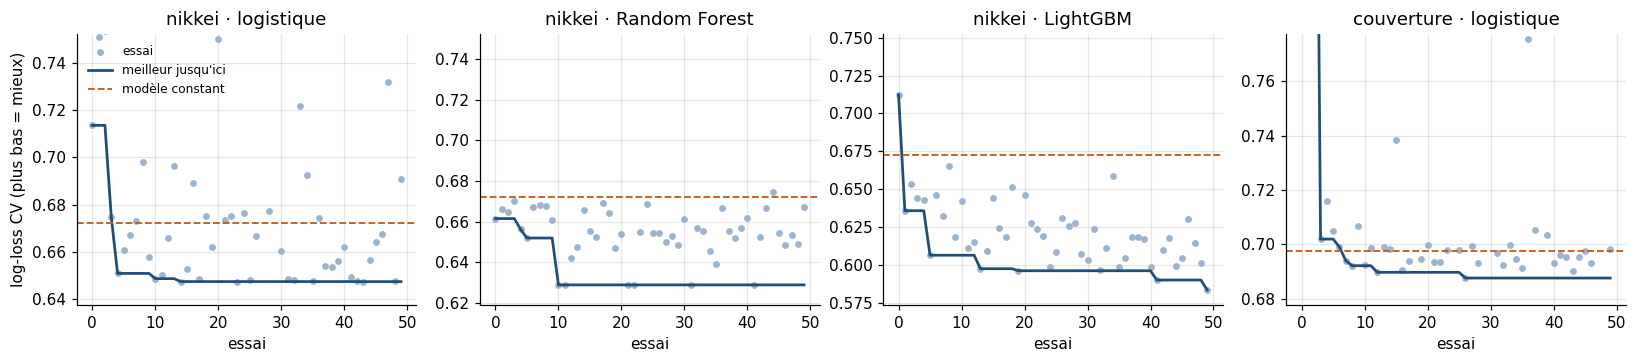

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=False)
titres = {"logit": "logistique", "rf": "Random Forest", "lgbm": "LightGBM"}
for ax, ((cible, nom), etude) in zip(axes, ETUDES.items()):
    valeurs = np.array([t.value for t in etude.trials])
    ax.scatter(range(len(valeurs)), valeurs, s=12, color="#9db4cf", label="essai")
    ax.plot(np.minimum.accumulate(valeurs), color="#1f4e79", lw=1.8, label="meilleur jusqu'ici")
    ax.axhline(REF_CV[cible]["logloss"], color="#c55a11", ls="--", lw=1.2, label="modèle constant")
    bas = min(valeurs.min(), REF_CV[cible]["logloss"]) - 0.01
    ax.set_ylim(bas, REF_CV[cible]["logloss"] + 0.08)
    ax.set_title(f"{cible} · {titres[nom]}")
    ax.set_xlabel("essai")
axes[0].set_ylabel("log-loss CV (plus bas = mieux)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "02_optuna_historique.png")
plt.show()

## 5. Comparaison des modèles retenus (exigence 4)

Mêmes métriques pour tous : log-loss (S2), Brier (S8) et PR-AUC de la classe positive (S7), d'abord en validation croisée sur l'entraînement, puis sur la validation 2022-2023. Le modèle constant est la référence sans compétence (S1). Chaque modèle retenu est réentraîné sur les 143 mois d'entraînement avant d'être jugé sur la validation.

In [10]:
lignes = []
MEILLEURS, PRED = {}, []
for cible, col in CIBLES.items():
    y_tr, y_va = train[col].astype(int), valid[col].astype(int)
    p_const = y_tr.mean()
    lignes.append({"cible": cible, "modèle": "constant", "log-loss CV": REF_CV[cible]["logloss"],
                   "Brier CV": REF_CV[cible]["brier"], "PR-AUC CV": REF_CV[cible]["pr_auc"],
                   "log-loss validation": log_loss(y_va, np.full(len(y_va), p_const), labels=[0, 1]),
                   "Brier validation": brier_score_loss(y_va, np.full(len(y_va), p_const)),
                   "PR-AUC validation": y_va.mean(), "proba moyenne validation": p_const})
    for (c, nom), etude in ETUDES.items():
        if c != cible:
            continue
        pipe = construire_pipeline(proposer(optuna.trial.FixedTrial(etude.best_params), nom)).fit(X_tr, y_tr)
        MEILLEURS[(cible, nom)] = pipe
        joblib.dump(pipe, RUNS / "models" / f"{cible}_{nom}.joblib")
        p_va = pipe.predict_proba(X_va)[:, 1]
        _, oof = evaluer_cv(construire_pipeline(proposer(optuna.trial.FixedTrial(etude.best_params), nom)), y_tr)
        t = etude.best_trial
        lignes.append({"cible": cible, "modèle": nom, "log-loss CV": t.value, "Brier CV": t.user_attrs["brier"],
                       "PR-AUC CV": t.user_attrs["pr_auc"], "log-loss validation": log_loss(y_va, p_va, labels=[0, 1]),
                       "Brier validation": brier_score_loss(y_va, p_va), "PR-AUC validation": average_precision_score(y_va, p_va),
                       "proba moyenne validation": p_va.mean()})
        PRED.append(pd.DataFrame({"cible": cible, "modele": nom, "bloc": "hors fold", "y": y_tr, "p": oof}).dropna())
        PRED.append(pd.DataFrame({"cible": cible, "modele": nom, "bloc": "validation", "y": y_va, "p": p_va}, index=valid.index))

COMPARAISON = pd.DataFrame(lignes).set_index(["cible", "modèle"])
pd.concat(PRED).rename_axis("date").to_csv(RUNS / "predictions_02.csv")
COMPARAISON.round(3)

log-loss CV  Brier CV  PR-AUC CV  log-loss validation  \
cible      modèle                                                            
nikkei     constant        0.672     0.240      0.396                0.681   
           logit           0.647     0.228      0.632                0.701   
           rf              0.629     0.219      0.595                0.742   
           lgbm            0.584     0.200      0.711                0.710   
couverture constant        0.697     0.252      0.500                0.669   
           logit           0.688     0.247      0.500                0.740   

                     Brier validation  PR-AUC validation  \
cible      modèle                                          
nikkei     constant             0.244              0.417   
           logit                0.253              0.489   
           rf                   0.273              0.440   
           lgbm                 0.257              0.524   
couverture constant             0.238              0.292   
           logit                0.274              0.292   

                     proba moyenne validation  
cible      modèle                              
nikkei     constant                     0.392  
           logit                        0.456  
           rf                           0.425  
           lgbm                         0.344  
couverture constant                     0.469  
           logit                        0.550

In [11]:
# Gain = log-loss du modèle constant moins log-loss du modèle : positif = le modèle fait mieux que la constante
colonnes = ["log-loss CV", "log-loss validation"]
reference = COMPARAISON[colonnes].xs("constant", level="modèle")
gain = reference.reindex(COMPARAISON.index, level="cible") - COMPARAISON[colonnes]
gain.columns = ["gain en CV", "gain en validation"]
gain.round(4)

gain en CV  gain en validation
cible      modèle                                  
nikkei     constant      0.0000              0.0000
           logit         0.0251             -0.0204
           rf            0.0435             -0.0611
           lgbm          0.0888             -0.0290
couverture constant      0.0000              0.0000
           logit         0.0098             -0.0715

## 6. Que disent les régressions logistiques ? (S2)

Les coefficients sont lus sur variables standardisées : une variable qui gagne un écart-type multiplie les odds de la classe positive par e<sup>coefficient</sup>. Pour le Nikkei, la classe positive est la **baisse** : un coefficient positif rend la baisse plus probable. Avec une pénalité L1, un coefficient nul veut dire que le Lasso a écarté la variable pour ce réglage, pas qu'elle est inutile (S3).

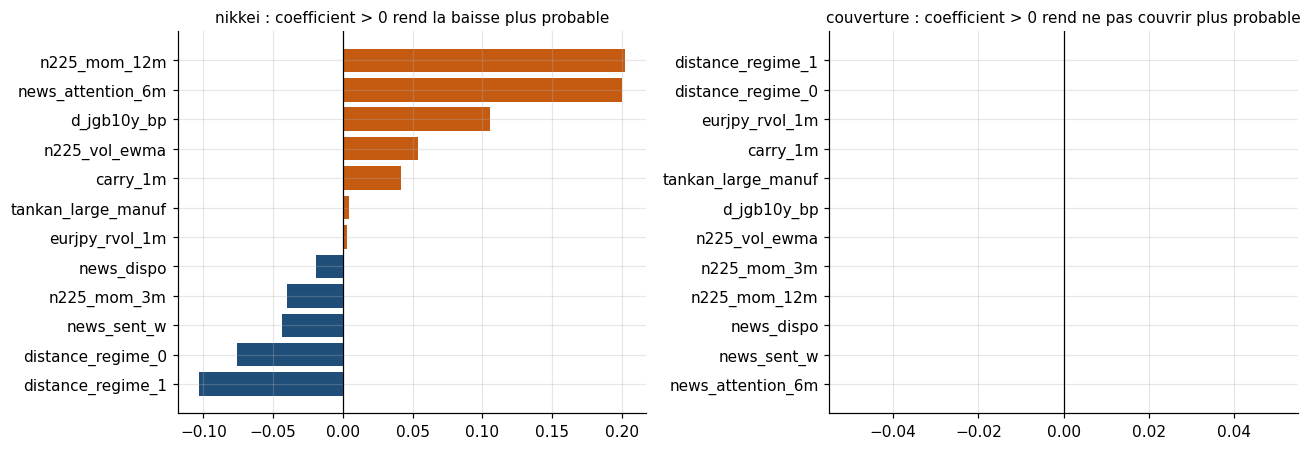

nikkei                            couverture  \
                   coefficient odds ratio par écart-type coefficient   
news_attention_6m        0.200                     1.222         0.0   
news_sent_w             -0.044                     0.957         0.0   
news_dispo              -0.019                     0.981         0.0   
n225_mom_12m             0.202                     1.224         0.0   
n225_mom_3m             -0.040                     0.961         0.0   
n225_vol_ewma            0.054                     1.055         0.0   
d_jgb10y_bp              0.106                     1.111         0.0   
tankan_large_manuf       0.005                     1.005         0.0   
carry_1m                 0.042                     1.043         0.0   
eurjpy_rvol_1m           0.003                     1.003         0.0   
distance_regime_0       -0.076                     0.927         0.0   
distance_regime_1       -0.103                     0.902         0.0   

                                              
                   odds ratio par écart-type  
news_attention_6m                        1.0  
news_sent_w                              1.0  
news_dispo                               1.0  
n225_mom_12m                             1.0  
n225_mom_3m                              1.0  
n225_vol_ewma                            1.0  
d_jgb10y_bp                              1.0  
tankan_large_manuf                       1.0  
carry_1m                                 1.0  
eurjpy_rvol_1m                           1.0  
distance_regime_0                        1.0  
distance_regime_1                        1.0

In [12]:
def coefficients(pipe):
    w = pipe.named_steps["model"].coef_[0]
    return pd.DataFrame({"coefficient": w, "odds ratio par écart-type": np.exp(w)}, index=NOMS_SORTIE)

COEFS = {cible: coefficients(MEILLEURS[(cible, "logit")]) for cible in CIBLES}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (cible, tab) in zip(axes, COEFS.items()):
    tab = tab.sort_values("coefficient")
    couleurs = ["#c55a11" if v > 0 else "#1f4e79" for v in tab["coefficient"]]
    ax.barh(tab.index, tab["coefficient"], color=couleurs)
    ax.axvline(0, color="black", lw=0.8)
    positif = "la baisse" if cible == "nikkei" else "ne pas couvrir"
    ax.set_title(f"{cible} : coefficient > 0 rend {positif} plus probable", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "02_coefficients_logistiques.png")
plt.show()
pd.concat(COEFS, axis=1).round(3)

## 7. Ce qu'on retient

- **En validation croisée, les trois modèles Nikkei battent le modèle constant** : log-loss 0,647 (logistique), 0,629 (Random Forest) et 0,584 (LightGBM), contre 0,672. Ce n'est pas un essai chanceux : 98 % des essais des modèles à arbres font mieux que la constante.
- **Sur la validation 2022-2023, aucun ne la bat, ni en log-loss ni en Brier** : 0,701, 0,742 et 0,710 contre 0,681. Leur PR-AUC reste pourtant au-dessus de la référence (0,489, 0,440 et 0,524 contre 0,417). Ils classent donc les mois à risque un peu mieux que le hasard, mais le niveau de leurs probabilités est faux sur cette période.
- **Deux explications, à donner dans le rapport.**
    1. Le réglage par Optuna sur 4 folds de 12 mois s'ajuste en partie au bruit de ces 48 mois. Plus le modèle est flexible, plus l'écart est grand : LightGBM gagne 0,089 en validation croisée et perd 0,029 en validation.
    2. 2022-2023 est un autre régime : la BoJ desserre son contrôle des taux longs et le portage redevient positif (notebook 01).
- **Ce que chaque modèle apporte (exigence 4).** En log-loss, la logistique est celle qui perd le moins sur la validation (−0,020). En classement, LightGBM est le meilleur (PR-AUC 0,524). Le Random Forest n'est meilleur sur aucun des deux.
- **La logistique raconte la même histoire que l'EDA.** Les variables qui rendent une baisse plus probable sont le volume anormal d'articles (odds × 1,22 par écart-type), le momentum 12 mois (× 1,22, lecture contrarienne) et la hausse du JGB 10 ans (× 1,11). Le sentiment FinBERT (× 0,96) et `news_dispo` (× 0,98) ne pèsent presque rien : le piège `news_dispo` et portage du notebook 01 ne se matérialise pas.
- **Solveur.** `liblinear` pénalisait l'intercept et tirait les probabilités vers 50 %. Avec `saga`, la probabilité de baisse moyenne sur la validation passe de 51 % à 46 %, pour 42 % observés.
- **Couverture : aucun signal.** Optuna retient une pénalité L1 si forte que tous les coefficients sont nuls : le « modèle » est une constante à 0,55. Elle bat la constante en validation croisée par hasard de découpage, et perd nettement sur la validation (0,740 contre 0,669). On garde donc la règle **« toujours couvert »** (manuel, section 9).

**Étape suivante (notebook 03).** Calibrer les probabilités par Platt sur la validation (S8) : le niveau est corrigé sans toucher au classement. Puis choisir les seuils acheter, neutre et vendre, et mesurer TP, FP, FN, precision, recall et F1. Le modèle final sera choisi sur la validation après calibration, et la moyenne des trois modèles sera testée.
